# Camera Stabilizer Network

### Contents

+ Imports
+ Data import
+ Data preprocessing (rotation generation)
+ Model and head constructions
+ Models (train set) evaluation
+ Final training with top contendors


In [227]:
import os
from PIL import Image
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.transforms import Compose
import cv2
from itertools import chain



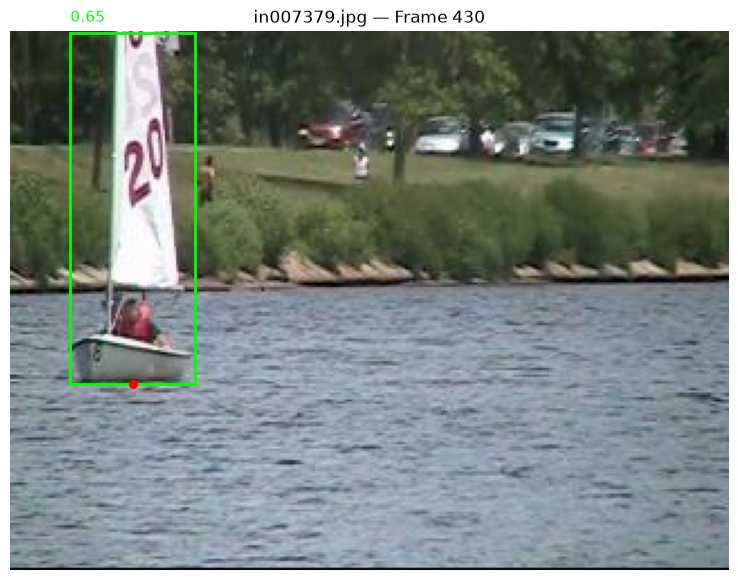

In [228]:
# Select video and frame
video_dir = Path("dataset/singleObjectDetection/test/Boat2")
frame_idx = 430

# Load image
image_paths = sorted((video_dir / "input").glob("*.jpg"))
image_path = image_paths[frame_idx]
image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)

# Load saved bounding boxes
df = pd.read_csv(video_dir / "boat_positions.csv")
detections = df[df["filename"] == image_path.name]

# Display image
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image)

for _, box in detections.iterrows():

    # Bounding box
    rect = patches.Rectangle(
        (box["x1"], box["y1"]),
        box["x2"] - box["x1"],
        box["y2"] - box["y1"],
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)

    # Tracking position
    ax.scatter(box["cx"], box["cy"], color="red", s=30)

    # Detection confidence
    ax.text(
        box["x1"], box["y1"] - 5,
        f'{box["confidence"]:.2f}',
        color="lime",
        fontsize=11
    )

ax.set_title(f"{image_path.name} — Frame {frame_idx}")
ax.axis("off")
plt.show()

## Dataset Structure

The CDnet (Change detection net) dataset contains 11 video categories with 4 to 6 videos in each category. This project chooses 3 videos with obtimal conditions for object detection with good weather conditions, small amount of shadows 

In [230]:
data_root = (Path.cwd() / "data" / "train").resolve()

train_path = data_root / "train"
val_path = data_root / "val"
small_train_path = data_root / "small-train"
small_val_path = data_root / "small-val"


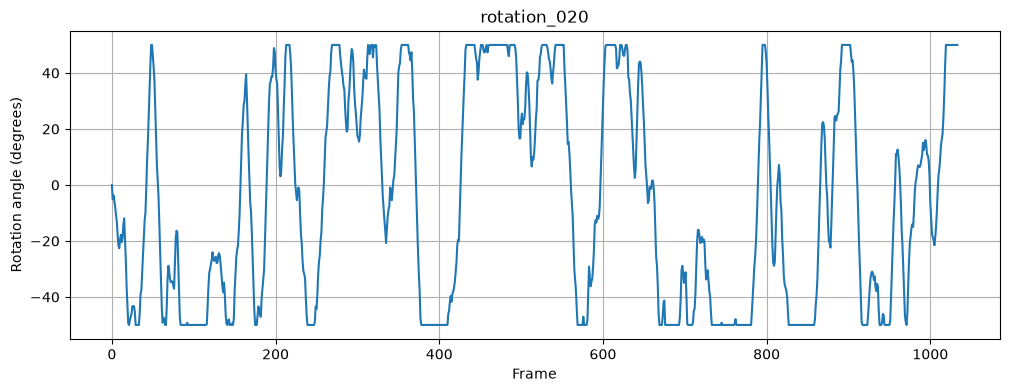

In [226]:
csv_path = Path("dataset/singleObjectDetection/test/Boat2/rotation_labels/rotation_020.csv")

# Load rotation trajectory
df = pd.read_csv(csv_path)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["angle_deg"])

plt.xlabel("Frame")
plt.ylabel("Rotation angle (degrees)")
plt.title(csv_path.stem)
plt.grid(True)
plt.show()